# Use Case 2: Exploratory Analysis and Visualization

**Objective.** Find trends and patterns in the crime data with Pandas, NumPy, Matplotlib and Seaborn.

**Input.** The `crime` table written by Notebook 01 (run it first), plus `chicago_city_community.csv` for community names.

| Task | Question it answers |
|---|---|
| 1 | How many crimes per year, and is crime rising or falling? |
| 2 | Which are the top 10 crime categories, with count and percentage? |
| 3 | What percentage of crimes end in an arrest? |
| 4 | How do crimes spread over month and day of week? |
| 5 | Which 10 community areas have the most crimes? |

Every chart is saved to `data/reports/use_case_2/`. The Flask site shows them on its Charts page.

**Read the results with care.** The supplied file is a small sample (498 records) that covers only a few dates. The notebook states this each time it affects a conclusion.

In [1]:
import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from db_config import RAW_DIR, get_engine, save_fig, write_report

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
FOLDER = "use_case_2"
sections = []   # (heading, text) pairs for the saved report

## Load the data from the database

The column names are mapped back to the names used in the brief (`Date`, `Year`, `Month`, `DayOfWeek`, `Arrest`).

In [2]:
engine, backend = get_engine()
df = pd.read_sql("SELECT * FROM crime", engine, parse_dates=["crime_date"])
df = df.rename(columns={"crime_date": "Date", "crime_year": "Year", "crime_month": "Month",
                        "crime_day_name": "DayOfWeek", "arrest": "Arrest"})
df["Arrest"] = df["Arrest"].astype(bool)

community = pd.read_csv(RAW_DIR / "chicago_city_community.csv")
print(f"{len(df)} crimes loaded from the {backend} database.")
df[["Date", "Year", "Month", "DayOfWeek", "primary_type", "Arrest", "community_code"]].head()

Using SQLite database chicago_crime_analysis.db (MySQL is not configured or not running).
498 crimes loaded from the sqlite database.


,Date,Year,Month,DayOfWeek,primary_type,Arrest,community_code
0,2016-05-03,2016,5,Tuesday,BATTERY,True,29
1,2016-05-03,2016,5,Tuesday,BATTERY,False,42
2,2016-05-03,2016,5,Tuesday,PUBLIC PEACE VIOLATION,False,25
3,2016-05-03,2016,5,Tuesday,BATTERY,False,25
4,2016-05-03,2016,5,Tuesday,THEFT,False,25


## Task 1: Crime trend over the years

`groupby("Year").size()` counts the crimes in each year. The table also shows which dates each year covers, because that decides how far the trend can be trusted.

In [3]:
crimes_per_year = df.groupby("Year").size()
coverage = df.groupby("Year")["Date"].agg(first="min", last="max", days="nunique")
coverage["crimes"] = crimes_per_year
coverage

,first,last,days,crimes
Year,,,,
2012,2012-01-01,2012-01-01,1,2
2013,2013-05-01,2013-05-01,1,1
2014,2014-11-01,2014-11-01,1,1
2015,2015-01-01,2015-11-24,3,4
2016,2016-01-01,2016-05-04,40,490


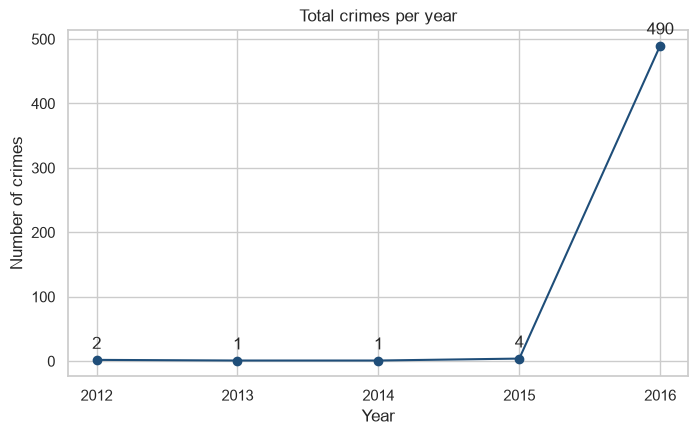

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(crimes_per_year.index, crimes_per_year.values, marker="o", color="#1f4e79")
for x, y in crimes_per_year.items():
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xticks(crimes_per_year.index)
ax.set_title("Total crimes per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of crimes")
save_fig(fig, FOLDER, "01_crimes_per_year.png")
plt.show()

### Visual interpretation: is crime increasing or decreasing?

In [5]:
first_year, last_year = crimes_per_year.index[0], crimes_per_year.index[-1]
first_n, last_n = int(crimes_per_year.iloc[0]), int(crimes_per_year.iloc[-1])
direction = "increased" if last_n > first_n else "decreased" if last_n < first_n else "stayed the same"
top_year = crimes_per_year.idxmax()
top_share = crimes_per_year.max() / len(df) * 100

text1 = (f"The line {direction} from {first_n} crime(s) in {first_year} to {last_n} in {last_year}. "
         f"{top_year} holds {int(crimes_per_year.max())} of {len(df)} records ({top_share:.2f}%). "
         "Dates covered per year: " + "; ".join(f"{y} ({r.days} distinct date(s), {r.first.date()} to {r.last.date()})"
                                                  for y, r in coverage.iterrows()) + ". ")
if top_share > 50:
    text1 += ("No year is fully covered and one year dominates, so the rise reflects which dates the file contains. "
              "This sample cannot show a real long-term trend. A full multi-year extract is needed for that.")
sections.append(("Task 1: Crime trend over years", text1))
display(Markdown(text1))

The line increased from 2 crime(s) in 2012 to 490 in 2016. 2016 holds 490 of 498 records (98.39%). Dates covered per year: 2012 (1 distinct date(s), 2012-01-01 to 2012-01-01); 2013 (1 distinct date(s), 2013-05-01 to 2013-05-01); 2014 (1 distinct date(s), 2014-11-01 to 2014-11-01); 2015 (3 distinct date(s), 2015-01-01 to 2015-11-24); 2016 (40 distinct date(s), 2016-01-01 to 2016-05-04). No year is fully covered and one year dominates, so the rise reflects which dates the file contains. This sample cannot show a real long-term trend. A full multi-year extract is needed for that.

## Task 2: Crime distribution by category

The top 10 values of `primary_type`, with the count and the percentage of all crimes.

In [6]:
type_counts = df["primary_type"].value_counts()
top10 = pd.DataFrame({"count": type_counts.head(10)})
top10["percentage"] = (top10["count"] / len(df) * 100).round(2)
top10

,count,percentage
primary_type,,
THEFT,105,21.08
BATTERY,85,17.07
CRIMINAL DAMAGE,49,9.84
OTHER OFFENSE,39,7.83
DECEPTIVE PRACTICE,38,7.63
ASSAULT,35,7.03
NARCOTICS,32,6.43
ROBBERY,30,6.02
CRIMINAL TRESPASS,17,3.41


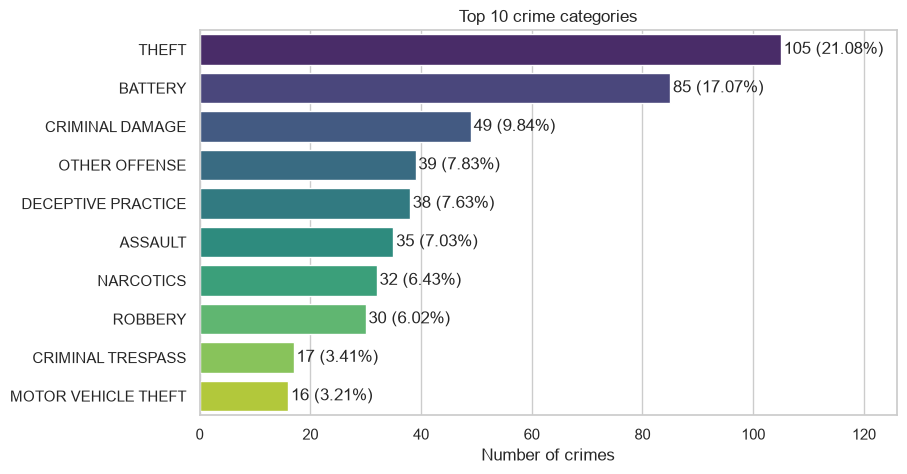

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = top10.reset_index()
sns.barplot(data=plot_data, y="primary_type", x="count", hue="primary_type", legend=False, palette="viridis", ax=ax)
for i, row in plot_data.iterrows():
    ax.text(row["count"] + 0.5, i, f"{row['count']} ({row['percentage']}%)", va="center")
ax.set_title("Top 10 crime categories")
ax.set_xlabel("Number of crimes")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["count"].max() * 1.2)
save_fig(fig, FOLDER, "02_top10_crime_categories.png")
plt.show()

In [8]:
top_name, top_count = type_counts.index[0], int(type_counts.iloc[0])
second_name, second_count = type_counts.index[1], int(type_counts.iloc[1])
text2 = (f"{top_name} is the most frequent category with {top_count} records ({top_count / len(df) * 100:.2f}%). "
         f"{second_name} follows with {second_count} ({second_count / len(df) * 100:.2f}%). "
         f"The top 10 of {type_counts.size} categories cover {top10['count'].sum() / len(df) * 100:.2f}% of the {len(df)} records.")
sections.append(("Task 2: Crime distribution by category", text2))
display(Markdown(text2))

THEFT is the most frequent category with 105 records (21.08%). BATTERY follows with 85 (17.07%). The top 10 of 23 categories cover 89.56% of the 498 records.

## Task 3: Arrests and crime outcomes

`Arrest` is True or False, so its mean is the share of crimes with an arrest. The table by year answers the question on consistency.

In [9]:
arrest_rate = df["Arrest"].mean() * 100
print(f"Arrest rate: {arrest_rate:.2f}% ({int(df['Arrest'].sum())} of {len(df)} crimes)")

by_year = df.groupby("Year")["Arrest"].agg(crimes="size", arrests="sum")
by_year["arrest_rate_%"] = (by_year["arrests"] / by_year["crimes"] * 100).round(2)
by_year

Arrest rate: 24.90% (124 of 498 crimes)


,crimes,arrests,arrest_rate_%
Year,,,
2012,2,2,100.00
2013,1,1,100.00
2014,1,0,0.00
2015,4,2,50.00
2016,490,119,24.29


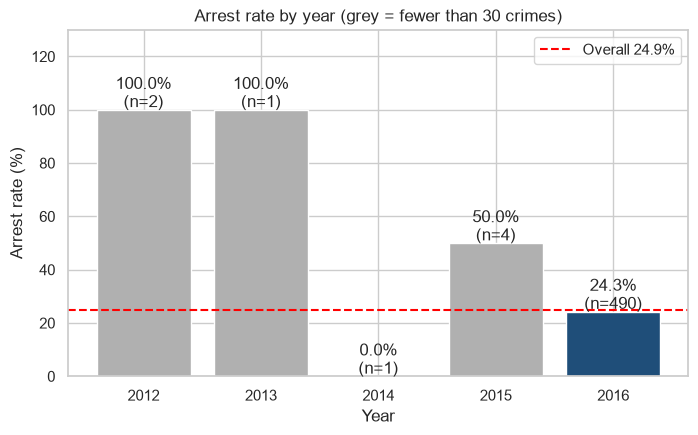

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#1f4e79" if n >= 30 else "#b0b0b0" for n in by_year["crimes"]]
bars = ax.bar(by_year.index.astype(str), by_year["arrest_rate_%"], color=colors)
for bar, n in zip(bars, by_year["crimes"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{bar.get_height():.1f}%\n(n={n})", ha="center")
ax.axhline(arrest_rate, color="red", linestyle="--", label=f"Overall {arrest_rate:.1f}%")
ax.set_ylim(0, max(by_year["arrest_rate_%"].max(), arrest_rate) * 1.3)
ax.set_title("Arrest rate by year (grey = fewer than 30 crimes)")
ax.set_xlabel("Year")
ax.set_ylabel("Arrest rate (%)")
ax.legend()
save_fig(fig, FOLDER, "03_arrest_rate_by_year.png")
plt.show()

In [11]:
reliable = by_year[by_year["crimes"] >= 30]
text3 = (f"{int(df['Arrest'].sum())} of {len(df)} crimes ({arrest_rate:.2f}%) ended in an arrest. "
         "Rate by year: " + "; ".join(f"{y}: {r['arrest_rate_%']}% (n={int(r['crimes'])})" for y, r in by_year.iterrows()) + ". ")
small = by_year[by_year["crimes"] < 30]
if len(reliable) >= 2:
    spread = reliable["arrest_rate_%"].max() - reliable["arrest_rate_%"].min()
    text3 += f"Among years with at least 30 crimes the rates differ by {spread:.1f} percentage points."
else:
    text3 += (f"Only {len(reliable)} year has at least 30 crimes. The other years have {int(small['crimes'].min())} to {int(small['crimes'].max())} records, "
              "so their rates of 0% to 100% are not meaningful. Consistency across years cannot be judged from this sample.")
sections.append(("Task 3: Arrests and crime outcomes", text3))
display(Markdown(text3))

124 of 498 crimes (24.90%) ended in an arrest. Rate by year: 2012: 100.0% (n=2); 2013: 100.0% (n=1); 2014: 0.0% (n=1); 2015: 50.0% (n=4); 2016: 24.29% (n=490). Only 1 year has at least 30 crimes. The other years have 1 to 4 records, so their rates of 0% to 100% are not meaningful. Consistency across years cannot be judged from this sample.

## Task 4: Heatmap of crime by month and day of week

`pd.crosstab` counts crimes for every month and weekday pair. Missing pairs are shown as 0 so all 12 months and 7 days appear. `sns.heatmap` draws the table.

In [12]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = pd.crosstab(df["Month"], df["DayOfWeek"]).reindex(index=range(1, 13), columns=day_order, fill_value=0)
pivot.index = [calendar.month_name[m] for m in pivot.index]
pivot

DayOfWeek,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
January,1,1,1,2,3,0,2
February,0,1,0,1,1,1,1
March,3,4,2,1,1,1,0
April,7,3,1,1,6,2,2
May,1,146,299,0,0,0,1
June,0,0,0,0,0,0,0
July,0,0,0,0,0,0,0
August,0,0,0,0,0,0,0
September,0,0,0,0,0,0,0
October,0,0,0,0,0,0,0


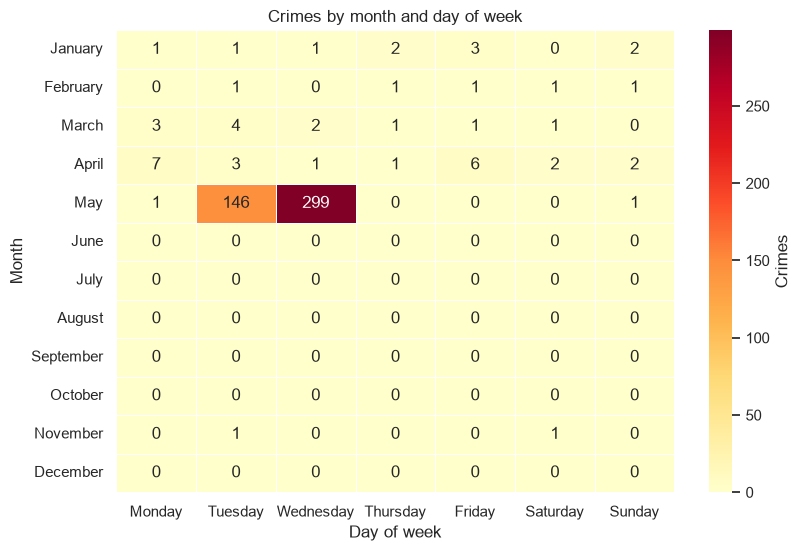

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, cbar_kws={"label": "Crimes"}, ax=ax)
ax.set_title("Crimes by month and day of week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Month")
save_fig(fig, FOLDER, "04_heatmap_month_vs_weekday.png")
plt.show()

In [14]:
month_totals = pivot.sum(axis=1)
busiest_month = month_totals.idxmax()
cell = pivot.stack().sort_values(ascending=False)
(top_cell_month, top_cell_day), top_cell_n = cell.index[0], int(cell.iloc[0])
months_with = [m for m, n in month_totals.items() if n > 0]
months_without = [m for m, n in month_totals.items() if n == 0]
month_share = month_totals.max() / len(df) * 100

text4 = (f"The busiest cell is {top_cell_month} / {top_cell_day} with {top_cell_n} crimes ({top_cell_n / len(df) * 100:.2f}%). "
         f"{busiest_month} has the most crimes of any month: {int(month_totals.max())} ({month_share:.2f}%). "
         f"Months with records: {', '.join(months_with)}. Months with none: {', '.join(months_without)}.")
if month_share > 50:
    text4 += " More than half of the records fall in one month, so the pattern shows which dates the sample contains, not a seasonal or weekly pattern."
sections.append(("Task 4: Crime heatmap", text4))
display(Markdown(text4))

The busiest cell is May / Wednesday with 299 crimes (60.04%). May has the most crimes of any month: 447 (89.76%). Months with records: January, February, March, April, May, November. Months with none: June, July, August, September, October, December. More than half of the records fall in one month, so the pattern shows which dates the sample contains, not a seasonal or weekly pattern.

## Task 5: Top community areas

Crimes are counted per `community_code` and the names come from `chicago_city_community.csv`.

In [15]:
by_area = (df.groupby("community_code").size().rename("crimes").reset_index()
            .merge(community[["community_code", "community_name"]], on="community_code", how="left")
            .sort_values(["crimes", "community_name"], ascending=[False, True]))
top10_areas = by_area.head(10).reset_index(drop=True)
top10_areas["percentage"] = (top10_areas["crimes"] / len(df) * 100).round(2)
top10_areas[["community_code", "community_name", "crimes", "percentage"]]

,community_code,community_name,crimes,percentage
0,25,Austin,34,6.83
1,23,Humboldt Park,20,4.02
2,8,Near North Side,20,4.02
3,68,Englewood,16,3.21
4,30,South Lawndale,16,3.21
5,43,South Shore,16,3.21
6,32,Loop,15,3.01
7,71,Auburn Gresham,14,2.81
8,6,Lake View,14,2.81
9,49,Roseland,14,2.81


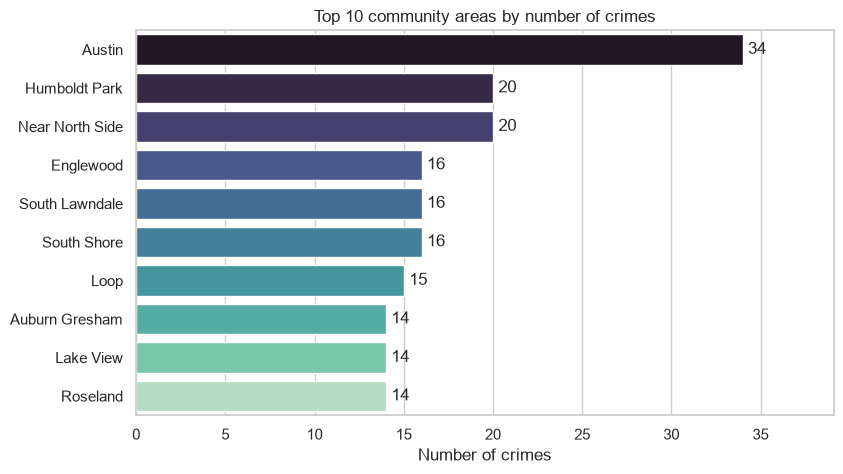

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top10_areas, y="community_name", x="crimes", hue="community_name", legend=False, palette="mako", ax=ax)
for i, row in top10_areas.iterrows():
    ax.text(row["crimes"] + 0.3, i, str(row["crimes"]), va="center")
ax.set_title("Top 10 community areas by number of crimes")
ax.set_xlabel("Number of crimes")
ax.set_ylabel("")
ax.set_xlim(0, top10_areas["crimes"].max() * 1.15)
save_fig(fig, FOLDER, "05_top10_community_areas.png")
plt.show()

In [17]:
first_area = top10_areas.iloc[0]
tied = top10_areas[top10_areas["crimes"] == first_area["crimes"]]["community_name"].tolist()
cut = int(top10_areas["crimes"].iloc[-1])
next_after = by_area.iloc[10]["crimes"] if len(by_area) > 10 else 0
text5 = (f"{first_area['community_name']} (code {int(first_area['community_code'])}) has the most crimes: {int(first_area['crimes'])} "
         f"({first_area['percentage']}%)" + (f", tied with {', '.join(tied[1:])}" if len(tied) > 1 else "") + ". "
         f"The top 10 areas cover {top10_areas['crimes'].sum() / len(df) * 100:.2f}% of all crimes. "
         f"{by_area['community_code'].nunique()} of {len(community)} community areas have at least one crime. "
         f"The 10th area has {cut} crimes and the next one has {int(next_after)}"
         + (", so the cut-off splits a tie. " if int(next_after) == cut else ". ")
         + "These are raw counts, not adjusted for population.")
sections.append(("Task 5: Top community areas", text5))
display(Markdown(text5))

Austin (code 25) has the most crimes: 34 (6.83%). The top 10 areas cover 35.94% of all crimes. 70 of 77 community areas have at least one crime. The 10th area has 14 crimes and the next one has 13. These are raw counts, not adjusted for population.

## Questions and answers

### Question 3 chart: crimes in each month
The bar chart counts crimes in all 12 months. The highest bar is highlighted.

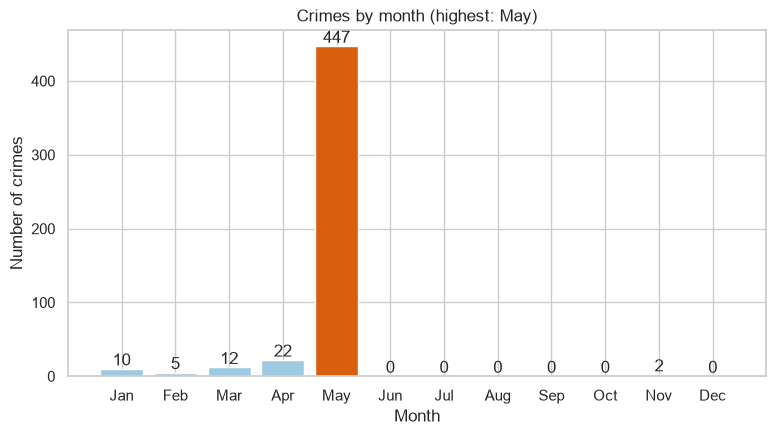

In [18]:
month_names = [calendar.month_name[m] for m in range(1, 13)]
by_month = df.groupby("Month").size().reindex(range(1, 13), fill_value=0)
by_month.index = [calendar.month_abbr[m] for m in by_month.index]
peak_abbr = by_month.idxmax()

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#d95f0e" if m == peak_abbr else "#9ecae1" for m in by_month.index]
bars = ax.bar(by_month.index, by_month.values, color=colors)
ax.bar_label(bars)
ax.set_title(f"Crimes by month (highest: {calendar.month_name[list(calendar.month_abbr).index(peak_abbr)]})")
ax.set_xlabel("Month")
ax.set_ylabel("Number of crimes")
save_fig(fig, FOLDER, "06_crimes_by_month.png")
plt.show()

### Question 2 chart: arrest rate across years
Each point is one year. The point size shows how many crimes the year has, and the dashed line is the overall rate. Small points are years with very few records.

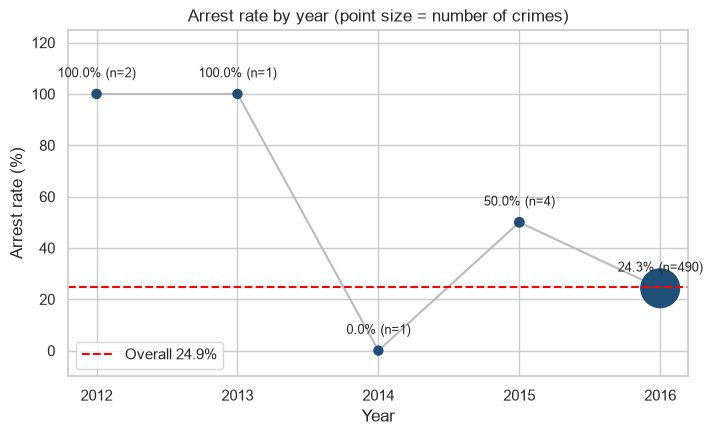

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_year.index, by_year["arrest_rate_%"], color="#bbbbbb", zorder=1)
ax.scatter(by_year.index, by_year["arrest_rate_%"], s=by_year["crimes"].clip(lower=1) * 1.5 + 40,
           color="#1f4e79", zorder=2)
for year, row in by_year.iterrows():
    ax.annotate(f"{row['arrest_rate_%']:.1f}% (n={int(row['crimes'])})", (year, row["arrest_rate_%"]),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=9)
ax.axhline(arrest_rate, color="red", linestyle="--", label=f"Overall {arrest_rate:.1f}%")
ax.set_xticks(by_year.index)
ax.set_ylim(-10, 125)
ax.set_title("Arrest rate by year (point size = number of crimes)")
ax.set_xlabel("Year")
ax.set_ylabel("Arrest rate (%)")
ax.legend(loc="lower left")
save_fig(fig, FOLDER, "07_arrest_rate_trend.png")
plt.show()

### Answers

In [20]:
q_sections = [
    ("Question 1: Which crime category is most frequent?",
     f"{top_name} is the most frequent crime category with {top_count} records ({top_count / len(df) * 100:.2f}%)."),
    ("Question 2: Is the arrest rate consistent across years?", text3),
    ("Question 3: Which month has the highest crime frequency?",
     f"{busiest_month} has the highest crime frequency with {int(month_totals.max())} crimes ({month_share:.2f}%)."
     + (" The sample covers only some dates, so this is not a seasonal result." if month_share > 50 else "")),
]
sections.extend(q_sections)
write_report(FOLDER, "use_case_2_interpretations.md", "Use Case 2 interpretations", sections)
for heading, body in q_sections:
    display(Markdown(f"**{heading}**\n\n{body}"))

**Question 1: Which crime category is most frequent?**

THEFT is the most frequent crime category with 105 records (21.08%).

**Question 2: Is the arrest rate consistent across years?**

124 of 498 crimes (24.90%) ended in an arrest. Rate by year: 2012: 100.0% (n=2); 2013: 100.0% (n=1); 2014: 0.0% (n=1); 2015: 50.0% (n=4); 2016: 24.29% (n=490). Only 1 year has at least 30 crimes. The other years have 1 to 4 records, so their rates of 0% to 100% are not meaningful. Consistency across years cannot be judged from this sample.

**Question 3: Which month has the highest crime frequency?**

May has the highest crime frequency with 447 crimes (89.76%). The sample covers only some dates, so this is not a seasonal result.